# Laboratorio · Predecir propinas con Python
**Regresión lineal · Ejercicio individual**

**Dataset:** `tips.csv`, 244 cuentas de restaurante. [Ver dataset en Kaggle](https://www.kaggle.com/datasets/sakshisatre/tips-dataset).

**Problema:** estimar `tip` (propina en USD) a partir de `total_bill` (cuenta en USD) y después comprobar si `size` (número de personas) aporta valor.

**Instrucciones:** ejecutar las actividades en orden, completar las celdas de código y responder las preguntas con resultados propios. El archivo CSV debe estar junto al notebook.

## 01 · Explorar el CSV
**Objetivo.** Cargar `tips.csv` y mostrar **cinco filas**, dimensiones, valores faltantes y resumen numérico.

*Pista:* `pd.read_csv()`, `.head()`, `.shape`, `.isna().sum()`, `.describe()`.

**Resultado esperado:** Una tabla y el resumen inicial.

In [ ]:

import pandas as pd

datos = pd.read_csv("tips.csv")

display(datos.head(5))

print("Dimensiones:", datos.shape)

print("\nValores faltantes:")
print(datos.isna().sum())

print("\nResumen estadístico:")
display(datos.describe())


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Dimensiones: (244, 7)

Valores faltantes:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Resumen estadístico:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 02 · Separar entradas y objetivo
**Objetivo.** Crear `X` con la cuenta total (`total_bill`) y `y` con la propina real (`tip`). Mostrar sus primeras filas y dimensiones.

*Pista:* `datos[["total_bill"]]` devuelve una tabla; `datos["tip"]` devuelve la serie objetivo.

**Resultado esperado:** Entradas y objetivos claramente identificados.

In [2]:
X = datos[["total_bill"]]

y = datos["tip"]

print("Entradas (X):")
display(X.head())

print("Objetivo (y):")
display(y.head())

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)


Entradas (X):


,total_bill
0,16.99
1,10.34
2,21.01
3,23.68
4,24.59


Objetivo (y):


0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64

Dimensiones de X: (244, 1)
Dimensiones de y: (244,)


## 03 · Crear entrenamiento y prueba
**Objetivo.** Reservar el 25 % de los registros para evaluar, usando `random_state=42`. Mostrar cuántas filas quedan en cada conjunto.

*Pista:* `train_test_split()` del módulo `sklearn.model_selection`.

**Resultado esperado:** Tamaños de `X_train`, `X_test`, `y_train`, `y_test`.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (183, 1)
X_test: (61, 1)
y_train: (183,)
y_test: (61,)


## 04 · Entrenar y predecir
**Objetivo.** Crear una regresión, ajustarla con entrenamiento y predecir las propinas del conjunto de prueba. Mostrar cinco predicciones.

*Pista:* `LinearRegression()`, `.fit()`, `.predict()`.

**Resultado esperado:** Cinco importes estimados.

In [6]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

print("Primeras cinco predicciones:")
print(y_pred[:5])


Primeras cinco predicciones:
[3.03019394 1.82116362 3.54772457 3.69434001 2.28398699]


## 05 · Evaluar los errores
**Objetivo.** Calcular **MAE, MSE, RMSE y R²** sobre los datos de prueba e imprimir sus valores.

*Pista:* `sklearn.metrics`; para RMSE se puede usar `mse ** 0.5`.

**Resultado esperado:** Cuatro indicadores numéricos.

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")


MAE: 0.6522
MSE: 0.7449
RMSE: 0.8631
R²: 0.4401


## 06 · Graficar datos y predicción
**Objetivo.** Construir una tabla de cinco valores reales y predichos. Dibujar los puntos reales y la recta del modelo, con nombres en los ejes y leyenda.

*Pista:* `pd.DataFrame()`, `plt.scatter()`, `plt.plot()`; ordenar X solo para dibujar la línea.

**Resultado esperado:** Tabla comparativa y gráfico.

,Real,Predicho
0,3.18,3.030194
1,2.00,1.821164
2,2.00,3.547725
3,5.16,3.694340
4,2.00,2.283987


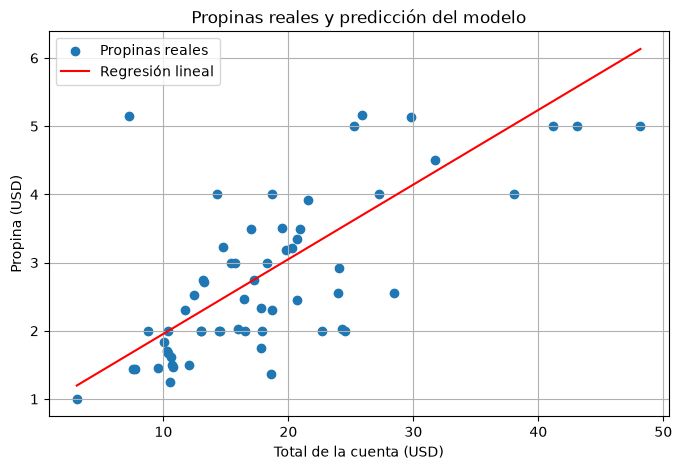

In [8]:
import matplotlib.pyplot as plt

comparacion = pd.DataFrame({
    "Real": y_test.to_numpy()[:5],
    "Predicho": y_pred[:5]
})

display(comparacion)

X_ordenado = X_test.sort_values("total_bill")
y_linea = modelo.predict(X_ordenado)

plt.figure(figsize=(8, 5))

plt.scatter(X_test["total_bill"], y_test, label="Propinas reales")
plt.plot(X_ordenado["total_bill"], y_linea, color="red", label="Regresión lineal")

plt.xlabel("Total de la cuenta (USD)")
plt.ylabel("Propina (USD)")
plt.title("Propinas reales y predicción del modelo")
plt.legend()
plt.grid(True)
plt.show()


## 07 · Inspeccionar residuos
**Objetivo.** Calcular `real − predicho`; graficar los residuos contra las predicciones, con una línea horizontal en cero.

*Pista:* `.to_numpy()`, `plt.scatter()`, `plt.axhline(0)`.

**Resultado esperado:** Gráfico de residuos.

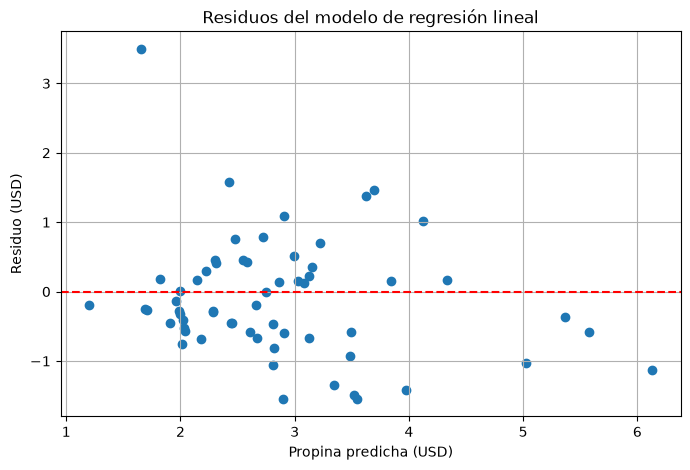

In [9]:
residuos = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuos)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Propina predicha (USD)")
plt.ylabel("Residuo (USD)")
plt.title("Residuos del modelo de regresión lineal")
plt.grid(True)
plt.show()


## 08 · Comparar una y dos entradas
**Objetivo.** Entrenar un segundo modelo usando `total_bill` y `size` juntos. Comparar **MAE, RMSE y R²** con el modelo inicial.

*Pista:* Definir `X2` con dos columnas y repetir la partición con el mismo `random_state`.

**Resultado esperado:** Comparación numérica de ambos modelos.

In [10]:
X2 = datos[["total_bill", "size"]]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.25, random_state=42
)

modelo2 = LinearRegression()
modelo2.fit(X2_train, y2_train)

y2_pred = modelo2.predict(X2_test)

mae2 = mean_absolute_error(y2_test, y2_pred)
mse2 = mean_squared_error(y2_test, y2_pred)
rmse2 = mse2 ** 0.5
r2_2 = r2_score(y2_test, y2_pred)

comparacion_modelos = pd.DataFrame({
    "Modelo": ["Solo total_bill", "total_bill + size"],
    "MAE": [mae, mae2],
    "RMSE": [rmse, rmse2],
    "R²": [r2, r2_2]
})

display(comparacion_modelos.round(4))


,Modelo,MAE,RMSE,R²
0,Solo total_bill,0.6522,0.8631,0.4401
1,total_bill + size,0.6734,0.8799,0.4180


## Preguntas de desarrollo
Responder con los resultados obtenidos y, cuando corresponda, hacer referencia a los gráficos.

1. ¿Qué información contiene `X` y cuál es el objetivo `y`? ¿Qué cambia en la entrada cuando se agrega `size`?
2. ¿Cómo interpretar el MAE del primer modelo en **dólares de propina**? Dar un ejemplo de su significado.
3. ¿Qué diferencia existe entre MAE y RMSE? ¿Qué sugiere que RMSE sea mayor?
4. ¿Qué representa el R² obtenido? Explicar por qué **no** es un porcentaje de predicciones correctas.
5. ¿Qué se observa en el gráfico de residuos? ¿Hay valores especialmente alejados de cero?
6. ¿El modelo con dos entradas mejora los resultados en test? Justificar con MAE, RMSE y R² y proponer una explicación posible.

### Respuestas

**1.** X contiene el total de la cuenta y la variable y es la propina que queremos predecir. Al agregar `size`, también consideramos la cantidad de personas en la mesa.

**2.** El MAE fue de 0,6522. Esto significa que el modelo se equivoca en promedio unos 65 centavos de dólar al predecir las propinas.

**3.** El MAE mide el error promedio, mientras que el RMSE le da más importancia a los errores grandes. Como el RMSE es mayor, significa que hubo algunas predicciones con errores más altos.

**4.** El R² fue de 0,4401, lo que significa que el modelo explica aproximadamente el 44 % de las diferencias entre las propinas. No significa que acierte el 44 % de las veces.

**5.** En el gráfico se observan puntos por encima y por debajo de cero. La mayoría no está muy lejos, pero hay algunos con errores grandes, especialmente uno cercano a 3,5 dólares.

**6.** No mejoró. Al agregar `size`, el MAE subió de 0,6522 a 0,6734, el RMSE de 0,8631 a 0,8799 y el R² bajó de 0,4401 a 0,4180. Esto puede deberse a que la cantidad de personas no aporta mucha información adicional para predecir la propina.